In [2]:
import numpy as np
import matplotlib.pyplot as plt

In [3]:
# Define current stock price stock price
S = 100

# Define option strike price
K = 100

# Define annual risk-free interest rate
r = 0.05

# Define annual voltility 
sigma = 0.2

#Define time until option expiry in years
T = 1

In [4]:
# Notation for normal distribution in numpy
Z = np.random.normal(0,1)
print(Z)

-2.0952063153228324


In [19]:
#follows log normal as brownian variable (normally distributed) is in the power
# not just a function of inputted parameteres, they scale with time
# solution to GBM obtained via itos lemma

ST = S*np.exp((r-((sigma)**2)/2)*T + (sigma*np.sqrt(T)*Z))
print(ST)

67.77063051979896


In [6]:
Z_values = np.random.normal(0, 1, 10000)
ST_values = S*np.exp((r-((sigma)**2)/2)*T + (sigma*np.sqrt(T)*Z_values))

In [7]:
print(len(ST_values))
print(ST_values[:10])

10000
[ 81.52495404 127.225391   105.48604493 122.26036828  89.89557651
  92.22476246  83.58949996 100.00510884  91.67435768  97.52029418]


In [8]:
payoffs = np.maximum(ST_values - K, 0)
payoffs[:10]

array([0.00000000e+00, 2.72253910e+01, 5.48604493e+00, 2.22603683e+01,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 5.10884051e-03,
       0.00000000e+00, 0.00000000e+00])

In [9]:
payoffs_average = np.mean(payoffs)
print(payoffs_average)

10.92076221149459


In [10]:
option_price = payoffs_average*np.exp(-r*T)
print(option_price)

10.388150353549145


In [11]:
simulation_number = np.array([100,1000,10000,100000])

In [12]:
import time
prices = []
runtimes = []
margins = []

for i in simulation_number:
    start = time.perf_counter()

    a = np.random.normal(0, 1, i)
    b = S*np.exp((r-(sigma)**2/2)*T + sigma*np.sqrt(T)*a)
    c = np.maximum(b - K, 0)
    d = np.mean(c)
    e = d*np.exp(-r*T)

    prices.append(e)

    # Calculate the 95% confidence interval margin
    discounted_payoffs = c * np.exp(-r*T)
    standard_error = np.std(discounted_payoffs, ddof=1) / np.sqrt(i)
    margin = 1.96 * standard_error

    margins.append(margin)

    elapsed = time.perf_counter() - start
    runtimes.append(elapsed)

# Display results
for i in range(len(simulation_number)):
    print(f"{simulation_number[i]} simulations:")
    print(f"  Estimated price: £{prices[i]:.4f}")
    print(f"  95% CI: £{prices[i]-margins[i]:.4f} to £{prices[i]+margins[i]:.4f}")
    print()

100 simulations:
  Estimated price: £11.5454
  95% CI: £8.4644 to £14.6264

1000 simulations:
  Estimated price: £9.4888
  95% CI: £8.5989 to £10.3786

10000 simulations:
  Estimated price: £10.4227
  95% CI: £10.1316 to £10.7137

100000 simulations:
  Estimated price: £10.4195
  95% CI: £10.3288 to £10.5103



In [13]:
from scipy.stats import norm

d1 = (np.log(S/K) + (r + sigma**2/2)*T) / (sigma*np.sqrt(T))
d2 = d1 - sigma*np.sqrt(T)

BS_price = S*norm.cdf(d1) - K*np.exp(-r*T)*norm.cdf(d2)

print(BS_price)

# Create an empty list to store pricing errors
errors = []

# Calculate the absolute error for each simulation count
for price in prices:
    error = abs(price - BS_price)
    errors.append(error)

# Display the errors
print(errors)


10.450583572185565
[np.float64(1.094827434711485), np.float64(0.9618064010580074), np.float64(0.0279272804099584), np.float64(0.031050039300740906)]


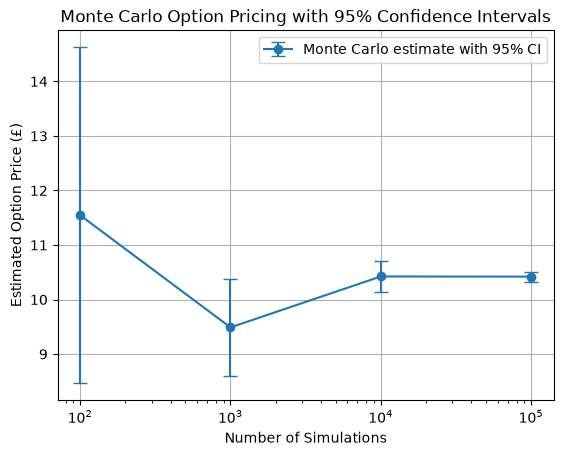

In [14]:
plt.errorbar(
    simulation_number,
    prices,
    yerr=margins,
    fmt="o-",
    capsize=5,
    label="Monte Carlo estimate with 95% CI"
)

plt.xscale("log")
plt.xlabel("Number of Simulations")
plt.ylabel("Estimated Option Price (£)")
plt.title("Monte Carlo Option Pricing with 95% Confidence Intervals")
plt.grid(True)
plt.legend()
plt.show()


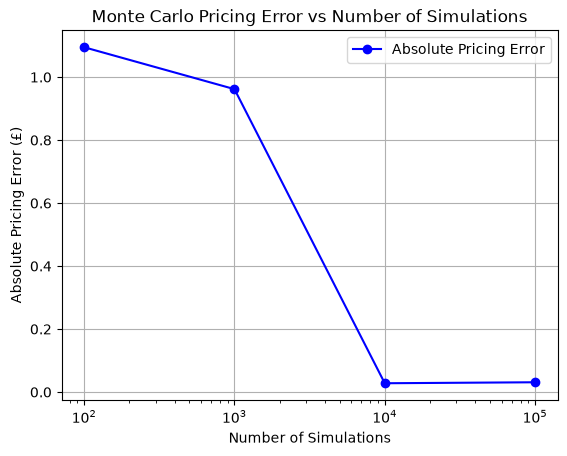

In [15]:
# Plot pricing errors for different simulation counts
plt.plot(simulation_number, errors, marker="o", color="blue", label="Absolute Pricing Error")

# Use a logarithmic scale for simulation counts
plt.xscale("log")

# Label the graph
plt.xlabel("Number of Simulations")
plt.ylabel("Absolute Pricing Error (£)")
plt.title("Monte Carlo Pricing Error vs Number of Simulations")

# Display grid and legend
plt.grid(True)
plt.legend()

plt.show()
